# Multi-Agent Reinforcement Learning with Iterative Sequential Action Selection (MARLISA)

This notebook trains CityLearn's **MARLISA** controller and compares its deterministic final episode with `BasicRBC` and independent SAC.

The experiment keeps the dataset, three buildings, 720-step horizon, random seed, SAC hyperparameters, training schedule, and KPI calculation fixed. Standard MARLISA uses CityLearn's district-coupled `MARL` reward, while independent SAC uses its local electricity reward. Each row therefore represents a complete controller approach.


## SAC versus MARLISA

Both controllers maintain one actor and two critics for every building. Independent SAC chooses each building's action from its local encoded observations. MARLISA adds:

1. a linear model that predicts each building's electricity demand after an action;
2. two coordination variables describing expected district demand and previously dispatched building capacity;
3. iterative action selection that passes coordination information through the building policies; and
4. PCA preprocessing after the initial exploration period.

The standard run uses CityLearn's `MARL` reward, which couples each building's reward to total district demand. This compares the complete SAC and MARLISA approaches, including their intended objectives. Because both the controller and reward change, any performance difference cannot be attributed to information sharing alone.

The installed CityLearn 3.0.2 implementation selects a policy using the coordination-iteration index during post-exploration action selection. With three buildings and two iterations, that bypasses a building policy. The project runner applies a narrow compatibility correction that selects `policy_net[building]`; all other MARLISA calculations remain unchanged. The correction is recorded in the run metadata.


In [19]:
PROJECT_ROOT

WindowsPath('C:/Users/tanka/Dropbox/08-1 NUS Master in Computing AI specialization/CS5546 AI Planning and Decision Making/02Assignment')

In [11]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.run_marlisa import run_marlisa

SCHEMA = PROJECT_ROOT / 'notebooks' / 'data' / 'schema.json'
OUTPUT_DIRECTORY = PROJECT_ROOT / 'outputs' / 'marlisa'
print(f'Project root: {PROJECT_ROOT}')
print(f'Schema exists: {SCHEMA.is_file()}')


Project root: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment
Schema exists: True


The schema defines the buildings, observations, available actions, and simulation period. The output directory stores the experiment results.

## Comparable configuration

The SAC network and optimization settings below match `02_Independent_SAC.ipynb`; the reward changes to CityLearn's coordinated `MARL` reward. `TRAINING_EPISODES = 3` gives one initial exploration episode, one training episode, and one deterministic evaluation episode. It verifies the implementation but is too short for a final result.


Each MARLISA building agent uses one actor to select control actions and two critics to independently estimate their long-term value. SAC takes the minimum of the two critic estimates to reduce Q-value overestimation and improve training stability.

In [12]:
SEED = 42
TRAINING_EPISODES = 3
REWARD = 'marl'

SAC_PARAMETERS = {
    'hidden_dimension': (256, 256),
    'discount': 0.99,
    'tau': 0.005,
    'alpha': 0.2,
    'learning_rate': 3e-4,
    'batch_size': 256,
    'replay_buffer_capacity': 100_000,
    'action_scaling_coefficient': 0.5,
    'reward_scaling': 5.0,
    'update_per_time_step': 1,
}

MARLISA_PARAMETERS = {
    'regression_buffer_capacity': 30_000, #--Stores up to 30,000 experience samples per building for training the electricity-demand prediction model.
    'start_regression_time_step': 2, #--Starts fitting the demand prediction model from time step 2.
    'regression_frequency': 2_500, #--Refits the demand prediction model every 2,500 time steps after its initial fitting.
    'information_sharing': True, #Allows agents to use shared coordination information, including predicted district demand and dispatched capacity.
    'pca_compression': 1.0, #Retains 100% of the encoded state dimensions during PCA, so there is effectively no dimensionality reduction
    'iterations': 2, #Performs two rounds of iterative sequential action selection at each time step.
}

pd.Series({
    'seed': SEED,
    'episodes': TRAINING_EPISODES,
    'reward': REWARD,
    **SAC_PARAMETERS,
    **MARLISA_PARAMETERS,
})


seed                                  42
episodes                               3
reward                              marl
hidden_dimension              (256, 256)
discount                            0.99
tau                                0.005
alpha                                0.2
learning_rate                     0.0003
batch_size                           256
replay_buffer_capacity            100000
action_scaling_coefficient           0.5
reward_scaling                       5.0
update_per_time_step                   1
regression_buffer_capacity         30000
start_regression_time_step             2
regression_frequency                2500
information_sharing                 True
pca_compression                      1.0
iterations                             2
dtype: object

MARLISA was configured with a 30,000-sample regression buffer, demand-model training beginning at time step 2 and recurring every 2,500 steps, information sharing enabled, full PCA dimensionality retained, and two rounds of iterative sequential action selection per time step.

CityLearn's coordinated `MARL` reward is:

$$
r_{i,t}=-\operatorname{sign}(E_{i,t})\,0.01E_{i,t}^{2}\max\left(\sum_j E_{j,t},0\right),
$$

where $E_{i,t}$ is Building $i$'s net electricity consumption and $\sum_j E_{j,t}$ is district net consumption. An importing building is penalized more strongly when both its own demand and district demand are high. A building exporting while the district still imports can receive a positive reward.


## Train and evaluate MARLISA

This is slower than independent SAC because MARLISA also fits demand models, applies PCA, and performs iterative coordinated action selection. The final episode uses deterministic actor outputs and does not update the networks.


In [13]:
result = run_marlisa(
    schema=SCHEMA,
    output_directory=OUTPUT_DIRECTORY,
    episodes=TRAINING_EPISODES,
    random_seed=SEED,
    reward=REWARD,
    **SAC_PARAMETERS,
    **MARLISA_PARAMETERS,
)

env = result['env']
agent = result['agent']
print(f'Device: {agent.device}')
print(f'Building policies: {len(agent.policy_net)}')
print(f'Reward function: {type(env.reward_function).__name__}')
print(f'Information sharing: {agent.information_sharing}')
print(f'Demand estimators fitted: {agent.regression_flag}')
print(f'PCA fitted: {agent.pca_flag}')
print(f"Outputs: {result['output_directory']}")


Device: cpu
Building policies: 3
Reward function: MARL
Information sharing: True
Demand estimators fitted: [2, 2, 2]
PCA fitted: [True, True, True]
Outputs: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment\outputs\marlisa


## Episode rewards

Reward is useful for monitoring learning within one fixed reward definition. The final point is deterministic evaluation. Do not compare reward numbers from runs that use different reward functions.


,episode,phase,building,min,max,sum,mean
0,1,initial_exploration,Building_1,-9.073,0.026,-176.325,-0.245
1,1,initial_exploration,Building_2,-14.879,0.072,-79.835,-0.111
2,1,initial_exploration,Building_3,-20.933,0.011,-167.137,-0.232
3,2,training,Building_1,-11.031,0.039,-81.681,-0.114
4,2,training,Building_2,-7.745,0.088,-48.577,-0.068
5,2,training,Building_3,-13.410,0.010,-119.958,-0.167
6,3,deterministic_evaluation,Building_1,-10.148,0.055,-58.361,-0.081
7,3,deterministic_evaluation,Building_2,-8.974,0.000,-37.145,-0.052
8,3,deterministic_evaluation,Building_3,-16.457,0.001,-104.894,-0.146


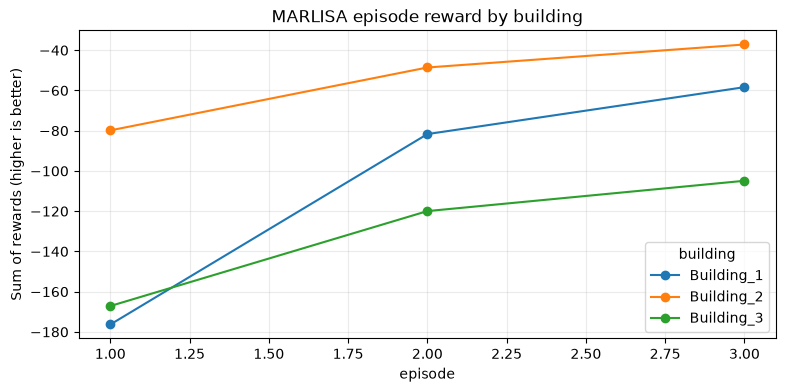

In [14]:
training_rewards = result['training_rewards']
display(training_rewards.round(3))

reward_plot = training_rewards.pivot(index='episode', columns='building', values='sum')
ax = reward_plot.plot(marker='o', figsize=(9, 4))
ax.set_title('MARLISA episode reward by building')
ax.set_ylabel('Sum of rewards (higher is better)')
ax.grid(alpha=0.25)
plt.show()


## MARLISA KPI results

The KPI table describes the final deterministic episode. CityLearn reports electricity, carbon, cost, peaks, ramping, and thermal discomfort independently of the reward used for learning. For normalized electricity KPIs, values below 1 improve on the corresponding no-control reference.

The current seed-42 development run using the `MARL` reward produced the following district ratios: carbon **0.657**, cost **0.626**, electricity **0.667**, daily peak **0.792**, and ramping **0.870**. Average building discomfort was **0.514**, worst-building discomfort was **0.895**, and the worst-best gap was **0.656**. The large gap means the comfort improvement was distributed unevenly.


In [15]:
display(result['kpi_table'].round(3))
display(result['fairness'].round(3))


name,Building_1,Building_2,Building_3,District
cost_function,,,,
all_time_peak_average,NaN,NaN,NaN,0.905
annual_normalized_unserved_energy_total,0.022,0.014,0.014,0.017
carbon_emissions_total,0.503,0.809,0.742,0.685
cost_total,0.477,0.774,0.710,0.654
daily_one_minus_load_factor_average,NaN,NaN,NaN,1.095
daily_peak_average,NaN,NaN,NaN,0.801
discomfort_cold_delta_average,0.003,0.449,0.132,0.195
discomfort_cold_delta_maximum,0.497,3.364,1.927,1.929
discomfort_cold_delta_minimum,0.000,0.000,0.000,0.000


,average_discomfort,worst_discomfort,best_discomfort,discomfort_gap,worst_building
0,0.511,0.846,0.307,0.539,Building_1


## Compare RBC, independent SAC, and MARLISA

The runner automatically loads existing RBC and SAC KPI files. Run notebooks `01` and `02` first if a controller column is absent. RBC has no learning reward. Independent SAC uses a local grid-import reward, while MARLISA uses the district-coupled `MARL` reward, so compare their common evaluation KPIs rather than their episode reward totals.


,seed,time_steps,episodes,reward
controller,,,,
BasicRBC,42,720,1,not used for RBC actions
Independent SAC,42,720,3,independent_sac
MARLISA,42,720,3,marl


,BasicRBC,Independent SAC,MARLISA,Carbon-aware MARLISA,Fair carbon-aware MARLISA
cost_function,,,,,
carbon_emissions_total,1.890,0.445,0.685,0.449,0.873
cost_total,1.843,0.418,0.654,0.422,0.856
electricity_consumption_total,1.900,0.452,0.695,0.456,0.877
daily_peak_average,1.329,0.715,0.801,0.716,0.910
ramping_average,0.924,0.889,0.861,0.887,1.098


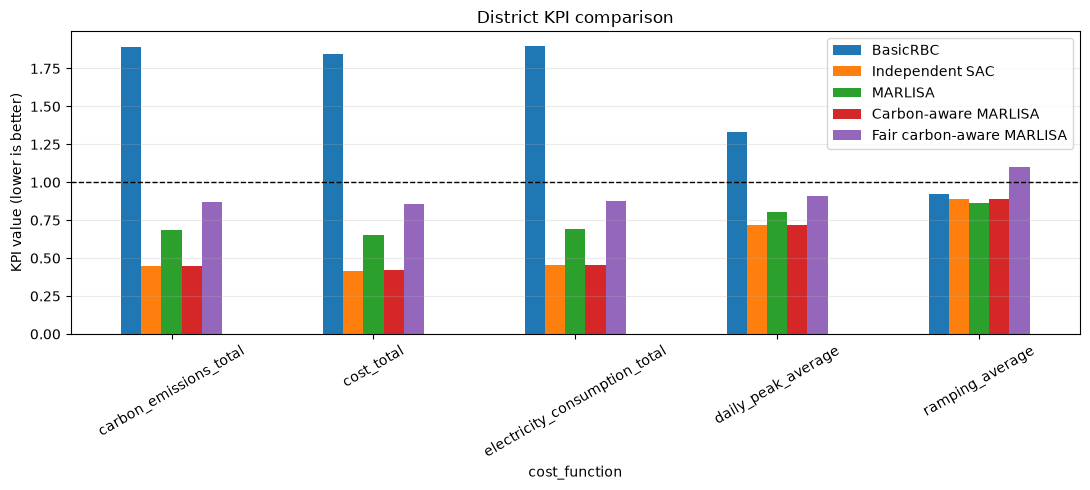

In [16]:
metadata_sources = {
    'BasicRBC': PROJECT_ROOT / 'outputs' / 'rbc' / 'metadata.json',
    'Independent SAC': PROJECT_ROOT / 'outputs' / 'independent_sac' / 'metadata.json',
}
contexts = []
for controller, path in metadata_sources.items():
    if path.is_file():
        metadata = json.loads(path.read_text(encoding='utf-8'))
        contexts.append({
            'controller': controller,
            'seed': metadata.get('random_seed'),
            'time_steps': metadata.get('episode_time_steps', metadata.get('time_steps')),
            'episodes': metadata.get('episodes', 1),
            'reward': metadata.get('reward_choice', 'not used for RBC actions'),
        })
contexts.append({
    'controller': 'MARLISA',
    'seed': result['metadata']['random_seed'],
    'time_steps': result['metadata']['episode_time_steps'],
    'episodes': result['metadata']['episodes'],
    'reward': result['metadata']['reward_choice'],
})
display(pd.DataFrame(contexts).set_index('controller'))

KEY_DISTRICT_KPIS = [
    'carbon_emissions_total',
    'cost_total',
    'electricity_consumption_total',
    'daily_peak_average',
    'ramping_average',
]

comparison = result['comparison']
available_kpis = [name for name in KEY_DISTRICT_KPIS if name in comparison.index]
display(comparison.loc[available_kpis].round(3))

ax = comparison.loc[available_kpis].plot.bar(figsize=(11, 5))
ax.axhline(1.0, color='black', linestyle='--', linewidth=1, label='No-control reference')
ax.set_ylabel('KPI value (lower is better)')
ax.set_title('District KPI comparison')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## Compare building-level discomfort fairness

The project defines operational fairness using the worst building's discomfort and the gap between the most and least uncomfortable buildings. Smaller values are better. This is fairness between simulated buildings, not demographic fairness.


In [17]:
controller_files = {
    'BasicRBC': PROJECT_ROOT / 'outputs' / 'rbc' / 'kpis.csv',
    'Independent SAC': PROJECT_ROOT / 'outputs' / 'independent_sac' / 'kpis.csv',
    'MARLISA': PROJECT_ROOT / 'outputs' / 'marlisa' / 'kpis.csv',
}

fairness_rows = []
for controller, path in controller_files.items():
    if not path.is_file():
        continue
    kpis = pd.read_csv(path)
    discomfort = kpis.loc[
        (kpis['level'] == 'building')
        & (kpis['cost_function'] == 'discomfort_proportion'),
        ['name', 'value'],
    ].dropna()
    if discomfort.empty:
        continue
    worst = discomfort.loc[discomfort['value'].idxmax()]
    fairness_rows.append({
        'controller': controller,
        'average_discomfort': discomfort['value'].mean(),
        'worst_discomfort': discomfort['value'].max(),
        'discomfort_gap': discomfort['value'].max() - discomfort['value'].min(),
        'worst_building': worst['name'],
    })

fairness_comparison = pd.DataFrame(fairness_rows).set_index('controller')
display(fairness_comparison.round(3))


,average_discomfort,worst_discomfort,discomfort_gap,worst_building
controller,,,,
BasicRBC,0.947,0.975,0.066,Building_1
Independent SAC,0.980,0.982,0.004,Building_1
MARLISA,0.511,0.846,0.539,Building_1


## Inspect coordinated actions

The action table contains the final deterministic episode. Look for differences between buildings and time periods. Coordination does not require identical actions; MARLISA uses district context to let each building choose an action suited to its own state.


,time_step,building,action,value
0,0,Building_1,dhw_storage,-0.308405
1,0,Building_1,electrical_storage,-0.292601
2,0,Building_1,cooling_device,0.092322
3,1,Building_1,dhw_storage,-0.304209
4,1,Building_1,electrical_storage,-0.283646
5,1,Building_1,cooling_device,0.092571
6,2,Building_1,dhw_storage,-0.244615
7,2,Building_1,electrical_storage,-0.251485
8,2,Building_1,cooling_device,0.104044
9,3,Building_1,dhw_storage,-0.250066


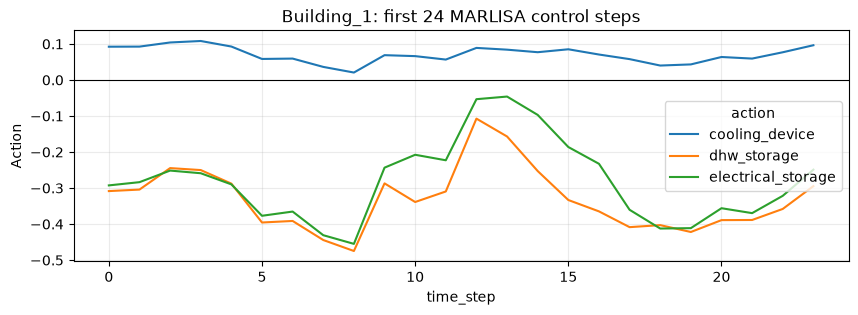

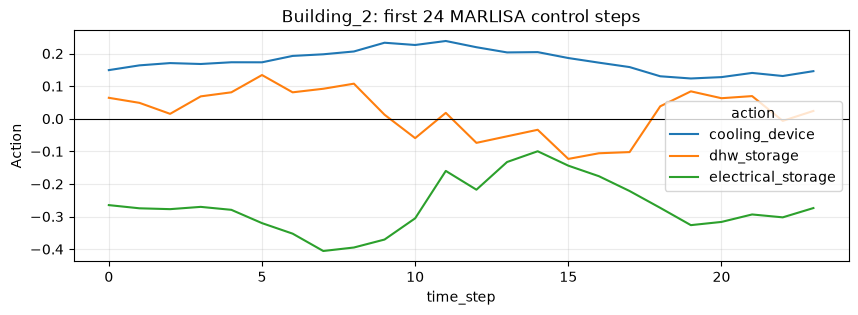

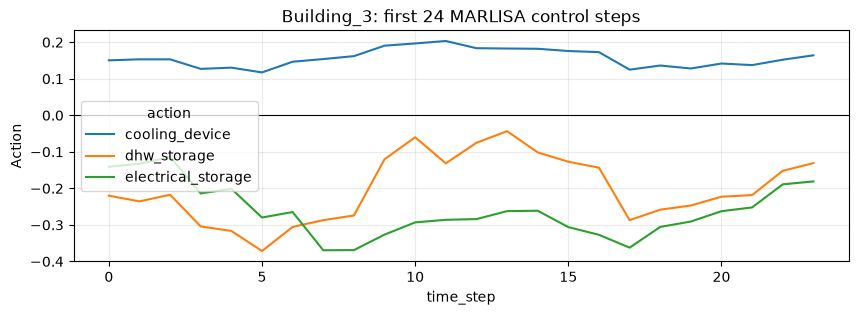

In [18]:
actions = result['actions']
display(actions.head(12))

first_day = actions.query('time_step < 24')
for building_name, building_actions in first_day.groupby('building'):
    action_plot = building_actions.pivot(index='time_step', columns='action', values='value')
    ax = action_plot.plot(figsize=(10, 3), title=f'{building_name}: first 24 MARLISA control steps')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel('Action')
    ax.grid(alpha=0.25)
    plt.show()


## Interpretation and next experiment

A three-episode result only confirms that the pipeline operates. For the report:

1. define separate training and held-out evaluation periods;
2. train SAC and MARLISA for the same number of transitions;
3. run both learned controllers with the same set of random seeds;
4. report mean and variation for carbon, cost, peak demand, average discomfort, worst-building discomfort, and discomfort gap; and
5. change one design choice at a time when introducing the carbon-aware and fairness rewards.

Generated files are stored in `outputs/marlisa/`, including training rewards, final actions and rewards, KPIs, fairness summary, controller comparison, metadata, and a checkpoint.
